<div class="title-slide">

# Make the Most of What You’ve Got: Deep Learning Optimization with PyTorch Profiler and Holistic Trace Analysis 

## Collin Wilson

</div>

# Getting started with `sn-torch-lab`

### This talk is given in a Jupyter notebook format. You can download it and all the materials to recreate the demo on GitHub:

```bash
git clone https://github.com/cwilson51/sn-torch-lab.git
```

### You can then install the repository as a package in a virtual environment. On Alliance Clusters:

```bash
module load StdEnv/2023 python/3.11 scipy-stack/2026a
virtualenv --no-download torch-labENV && source torch-labENV/bin/activate
pip install --no-index upgrade pip

git clone https://github.com/cwilson51/sn-torch-lab.git
pip install --no-index ./sn-torch-lab
```

<div class="pt-slide">
    
# What we'll cover today

- ## PyTorch Profiler revisited
    - ### Inline profiling
    - ### Generating traces
- ## Examining traces and simple optimizations
- ## Holistic trace analysis (HTA)
    - ### Single GPU
    - ### Distributed workloads
- ## Trace Analysis with Brine
</div>

<div class="pt-slide">
    
# PyTorch Profiler

- ## Built-in module of PyTorch
- ## Can profile run times, memory and generate detailed traces of PyTorch code
    - ### see layer-by-layer breakdown of model performance
- ## Both CPU and GPU profiling
- ## Code modification required - wrap code with a context manager
- ## Works for NVIDIA and AMD GPUs; separate tool for Apple MPS
- ## Today’s live profiles are with the H100 1g.10gb MIG flavour on Nibi
</div>

# Primary components of PyTorch profiler code

```python
from torch.profiler import ProfilerActivity, profile, record_function, schedule
```
- ### `ProfilerActivity` - we must pass the profiler a list of activities to profile. Here we'll profile the CPU and GPU if available
- ### `profile` - the profile object used to create and store the profile during execution
- ### `record_function` - context manager we can use to label sections of code . e.g 'training' and 'inference' or 'forward-pass' and 'backward-pass'
- ### `schedule` - schedule is used to control generating profiles over several iterations, we'll see more on this later

# Working example

## ResNet50 on random inputs

In [10]:
import torch
from torch.utils.data import DataLoader
from torch.profiler import ProfilerActivity, profile, record_function, schedule

from torchvision.models import resnet50
from torchvision.datasets import FakeData
from torchvision import transforms

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

activities = [ProfilerActivity.CPU] 
if torch.cuda.is_available():
    device = "cuda"
    activities += [ProfilerActivity.CUDA]

### Model and optimizer

In [5]:
model = resnet50()
model.to(device)

loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

### Data

In [11]:
train_ds = FakeData(
    size=10_000,                 # number of samples
    image_size=(3, 224, 224),
    num_classes=1000,
    transform=transforms.ToTensor(),
)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True,
                          num_workers=4, pin_memory=True)

### Run a simple profile

In [16]:
inputs, labels = next(iter(train_loader))
inputs, labels = inputs.to(device), labels.to(device)

with profile(activities=activities, record_shapes=True) as prof:

    model.train()
    with record_function("model_training"): # record_function can be used to get an aggregate measure of code sections and label them in traces
        outputs = model(inputs)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()
        
    model.eval()
    with record_function("model_inference"):
        model(inputs)

    prof.step() # !!! Step the profiler !!!

USDT:2026-11-17 15:54:44 2270237:2270237 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-17 15:54:45 2270237:2270237 SyncActivityProfilerHandler.cpp:46] profiler_stop


### Results:

In [10]:
print(prof.key_averages().table(sort_by="cpu_time_total", row_limit=10))

-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                         model_training        32.48%        3.060s        66.12%        6.230s        6.230s       0.000us         0.00%      88.278ms      88.278ms             1  
                                           aten::conv2d         0.00%     215.281us        31.95%        3.010s      28.397ms       0.000us         0.00%      72.990ms     688.580us           106  
         

## Reduced for readability:
```
-------------------------------------------------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CUDA   Self CUDA %   CUDA time avg   # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  
                                         model_training       0.000us         0.00%      88.278ms             1  
                                           aten::conv2d       0.000us         0.00%     688.580us           106  
                                      aten::convolution       0.000us         0.00%     688.580us           106  
                                     aten::_convolution       0.000us         0.00%     688.580us           106  
                                aten::cudnn_convolution      72.990ms        22.33%     688.580us           106  
autograd::engine::evaluate_function: CudnnBatchNormB...       0.000us         0.00%     736.648us            53  
                                CudnnBatchNormBackward0       0.000us         0.00%     736.648us            53  
                        aten::cudnn_batch_norm_backward      39.042ms        11.94%     736.648us            53  
autograd::engine::evaluate_function: ConvolutionBack...       0.000us         0.00%       1.795ms            53  
                                   ConvolutionBackward0       0.000us         0.00%       1.590ms            53  
-------------------------------------------------------   ------------  ------------  ------------  ------------  
Self CPU time total: 9.422s
Self CUDA time total: 326.916ms
```


# Exporting traces

- ## Profiles are most useful as traces that can be analyzed with other tools
- ## We can export traces as .JSON files with `prof.export_chrome_trace("trace.json")`

In [17]:
prof.export_chrome_trace("example-traces/live/trace.json")

In [20]:
! ls -lh example-traces/live

total 3.8M
-rw-r----- 1 c7wilson def-c7wilson 3.8M Nov 17 15:54 trace.json


# `schedule`

- ## When profiling longer training runs, profiles can get very large.
- ## We can capture select iterations using a `schedule`:
```python
               my_schedule = schedule(skip_first=10,
                                      wait=5,
                                      warmup=5,
                                      active=5,
                                      repeat=1)

```
- ## Profiler skips the first `skip_first` steps, then waits `wait` steps
- ## Starting the profile can skew results, so the profiler starts and does a `warmup`
- ## The profiler is active for `active` steps
- ## The profiler can repeat a cycle of `wait` + `warmup` + `active` as set by the user with `repeat`

In [23]:
my_schedule = schedule(skip_first=0,
                       wait=1,
                       warmup=2,
                       active=2,
                       repeat=2)


with profile(activities=activities, schedule=my_schedule, record_shapes=True) as prof:

    model.train()
    for _ in range(10):
    
        inputs, labels = next(iter(train_loader))
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()

        prof.step()


USDT:2026-11-17 16:02:20 2270237:2270237 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-17 16:02:21 2270237:2270237 SyncActivityProfilerHandler.cpp:46] profiler_stop
USDT:2026-11-17 16:02:22 2270237:2270237 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-17 16:02:23 2270237:2270237 SyncActivityProfilerHandler.cpp:46] profiler_stop


# Using trace handlers

- ## As we've seen, the profile only holds one cycle at a time
- ## We can define a trace handler to print results and/or export traces after each cycle
- ## The trace handler function is passed to the profiler using the `on_trace_ready` argument

## Example:

In [34]:
sort_by_keyword = "self_" + device + "_time_total"

def trace_handler(p):
    output = p.key_averages().table(sort_by=sort_by_keyword, row_limit=1).splitlines()[-2:]
    print(output)
    p.export_chrome_trace(f"example-traces/live/trace_{p.step_num}.json")

with profile(activities=activities, schedule=my_schedule, record_shapes=True, on_trace_ready=trace_handler) as prof:

    model.train()
    for _ in range(10):
    
        inputs, labels = next(iter(train_loader))
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()

        prof.step()

USDT:2026-11-17 16:12:02 2270237:2270237 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-17 16:12:03 2270237:2270237 SyncActivityProfilerHandler.cpp:46] profiler_stop


['Self CPU time total: 873.733ms', 'Self CUDA time total: 726.612ms']


USDT:2026-11-17 16:12:05 2270237:2270237 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-17 16:12:05 2270237:2270237 SyncActivityProfilerHandler.cpp:46] profiler_stop


['Self CPU time total: 893.256ms', 'Self CUDA time total: 726.481ms']


In [29]:
! ls -lh example-traces/live

total 18M
-rw-r----- 1 c7wilson def-c7wilson 6.7M Nov 17 16:05 trace_10.json
-rw-r----- 1 c7wilson def-c7wilson 6.7M Nov 17 16:05 trace_5.json
-rw-r----- 1 c7wilson def-c7wilson 3.8M Nov 17 15:54 trace.json


# Examining traces and simple optimizations

## Traces

- ## JSON traces are viewable at [ui.perfetto.dev](ui.perfetto.dev)
- ## The traces we'll view are all single GPU traces with ResNet50 on a synthetic image dataset designed to mimic ImageNet using an H100 1g_10GB MIG on Nibi
- ## Traces can be downloaded from [nextcloud](https://nextcloud.sharcnet.ca/s/smYAE6DynAEQWpn)
- ## If you've installed this repo, you can also generate the single-GPU examples on your own system or on a cluster with

```bash
torch-lab generate-example-traces
```

# Examining traces and simple optimizations

## Optimizations

- ## The example traces cover several simple optimizations
    - ### Serial, `num_workers` unset (defaults to `num_workers=0`)
    - ### Serial, `num_workers=1`, with pinned memory
    - ### Serial, `num_workers=1`, compiled with `torch.compile`
    - ### Threaded `num_workers=2`, compiled
- ## We don't have time to cover these optimizations in detail, but if you are interested, you can attend my PyTorch course as part of SHARCNET's Intro ARC series at the end of February. Sign up at training.sharcnet.ca! 


# Holistic Trace Analysis

- ## Holistic Trace Analysis (HTA) is a package from the developers of PyTorch for gathering important information from PyTorch profiler traces
- ## NOTE: The PyPI Name for HTA has changed to `traceinsight` so `pip install HolisticTraceAnalysis` will only give you up to `v0.5.0`!
- ## It is designed for use in Jupyter notebooks, but can be use in scripts as well


## Let's look at our last model with `hta`:

In [5]:
from hta.trace_analysis import TraceAnalysis
trace_dir = "example-traces/single-gpu/threaded-compiled-amp/"
analyzer = TraceAnalysis(trace_dir=trace_dir)

Parsed example-traces/single-gpu/threaded-compiled-amp/27686165_train_batch_64_nworkers_2_compiled_amp_trace.json time = 0.46 seconds 
Rounding down ns resolution events due to issue with events overlapping. ts dtype = float64, dur dtype = float64.Please see https://github.com/pytorch/pytorch/pull/122425
Parsed example-traces/single-gpu/threaded-compiled-amp/27686165_train_batch_64_nworkers_2_compiled_amp_trace.json backend=ParserBackend.JSON in 1.33 seconds; current PID:24278
Overall parsing of example-traces/single-gpu/threaded-compiled-amp/27686165_train_batch_64_nworkers_2_compiled_amp_trace.json in 2.45 seconds; current PID:24278
leaving parse_multiple_ranks duration=2.50 seconds
leaving parse_traces duration=2.50 seconds


## We noted that the GPU was once again idle after the optimizations, we can check this with `hta`:

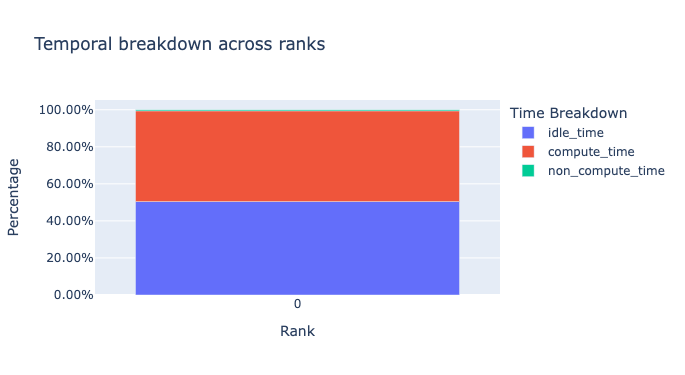

In [10]:
temporal_breakdown_df = analyzer.get_temporal_breakdown()

In [15]:
print(temporal_breakdown_df['non_compute_time_pctg'].values[0])

0.62


## HTA let's us look into the idle time further:

In [ ]:
idle_time_df, _ = analyzer.get_idle_time_breakdown()

- ## `host_wait`: GPU is waiting on the CPU, could be data starved
- ## `kernel_wait`: overhead associated with launching consecutive kernels on the GPU 
- ## `other`: unattributable idle time

## HTA is nice for some single GPU but really useful for Multi-GPU traces

In [34]:
trace_dir = "example-traces/multi-gpu/1_node_4_gpus/"
analyzer = TraceAnalysis(trace_dir=trace_dir)

Parsed example-traces/multi-gpu/1_nodes_4_gpus/DDP_rank_1_trace.json time = 0.35 seconds 
Parsed example-traces/multi-gpu/1_nodes_4_gpus/DDP_rank_2_trace.json time = 0.35 seconds 
Parsed example-traces/multi-gpu/1_nodes_4_gpus/DDP_rank_0_trace.json time = 0.35 seconds 
Parsed example-traces/multi-gpu/1_nodes_4_gpus/DDP_rank_3_trace.json time = 0.36 seconds 
Rounding down ns resolution events due to issue with events overlapping. ts dtype = float64, dur dtype = float64.Please see https://github.com/pytorch/pytorch/pull/122425
Rounding down ns resolution events due to issue with events overlapping. ts dtype = float64, dur dtype = float64.Please see https://github.com/pytorch/pytorch/pull/122425
Rounding down ns resolution events due to issue with events overlapping. ts dtype = float64, dur dtype = float64.Please see https://github.com/pytorch/pytorch/pull/122425
Rounding down ns resolution events due to issue with events overlapping. ts dtype = float64, dur dtype = float64.Please see htt

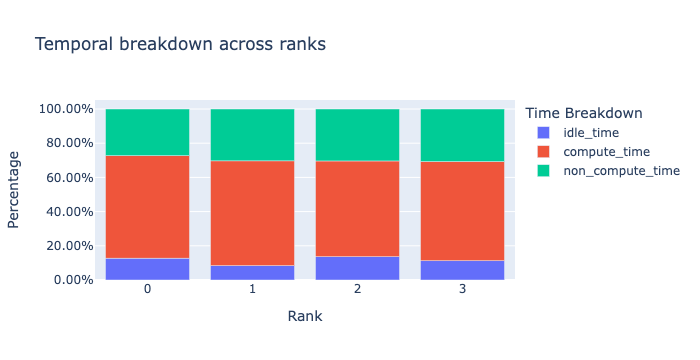

In [35]:
temporal_breakdown_df = analyzer.get_temporal_breakdown()

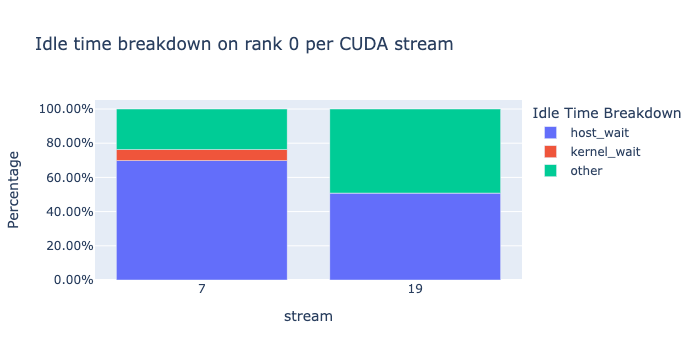

In [38]:
idle_time_df, _ = analyzer.get_idle_time_breakdown()

## Kernel Breakdown

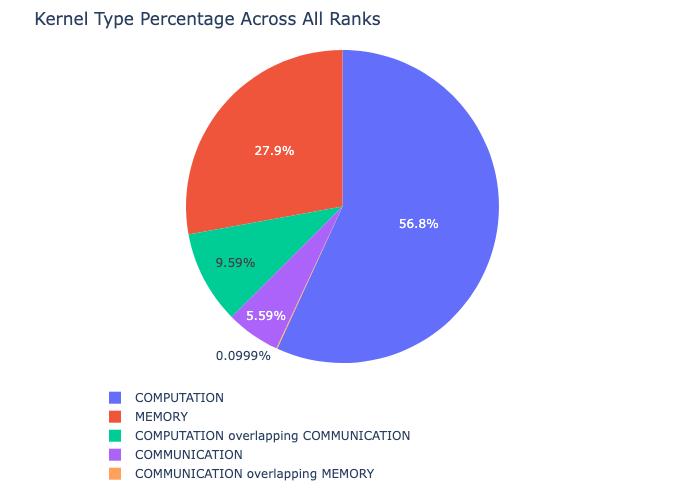

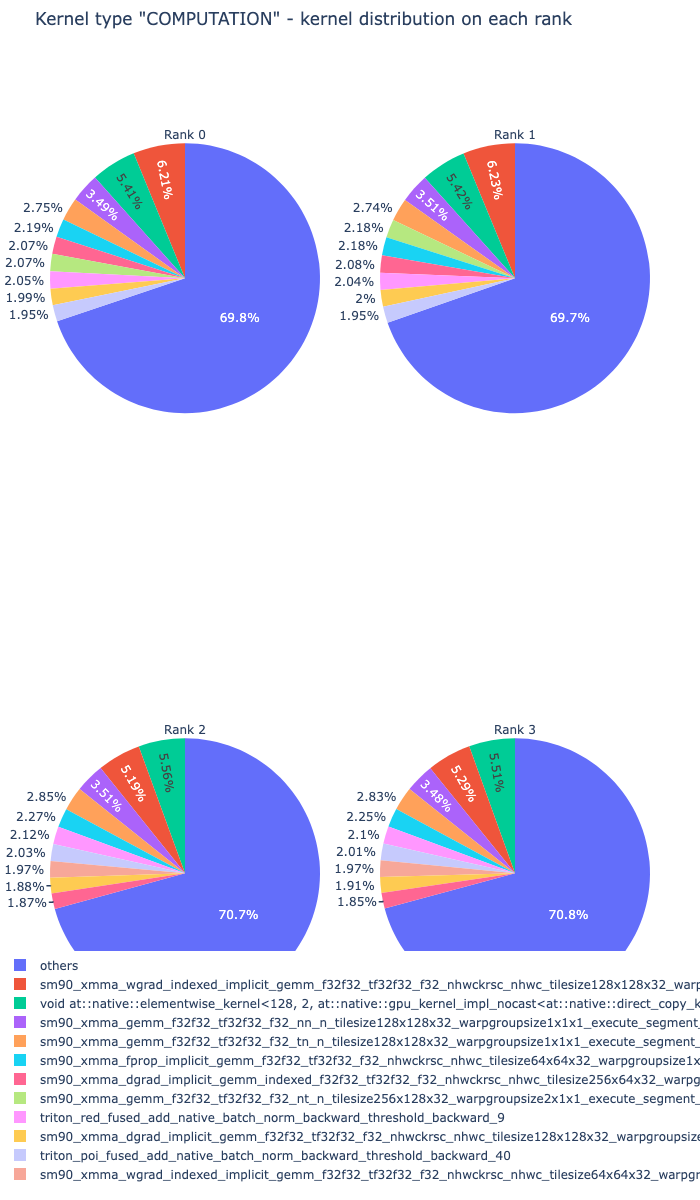

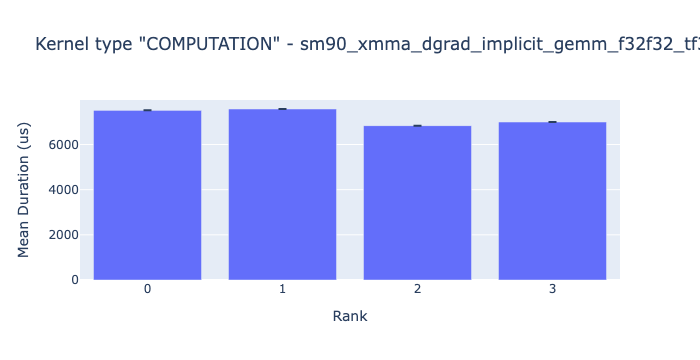

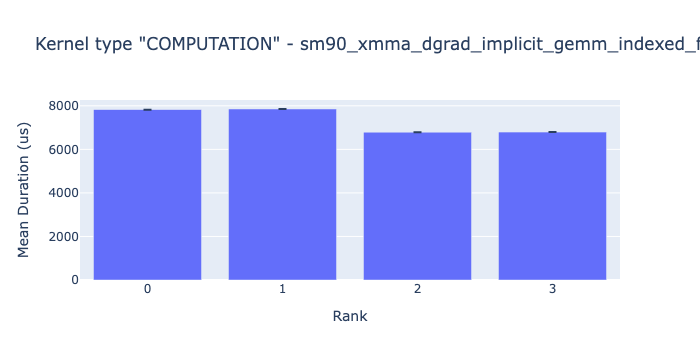

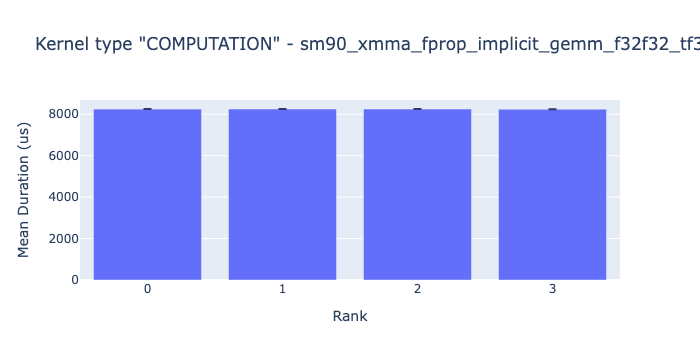

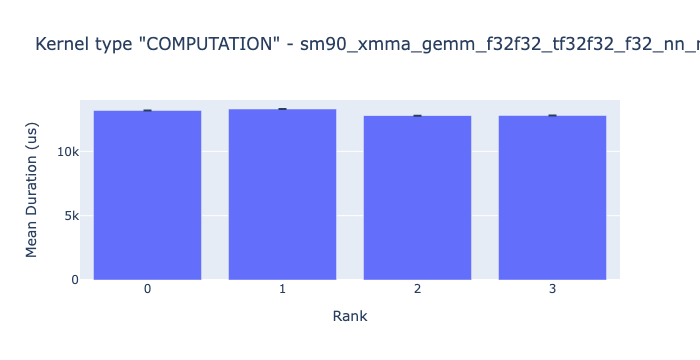

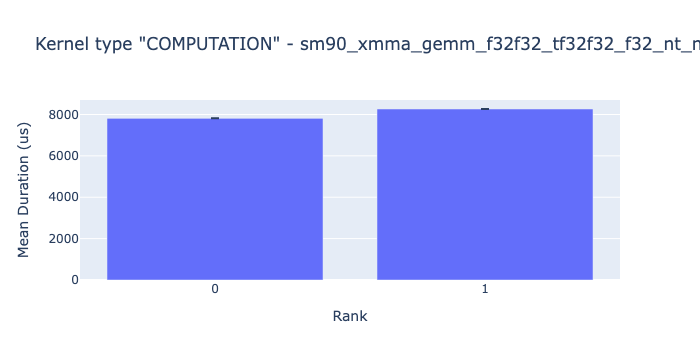

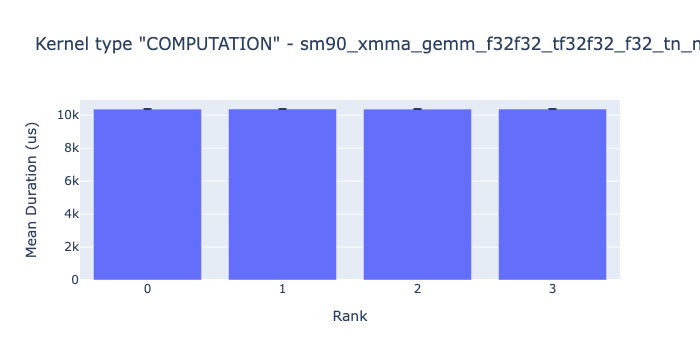

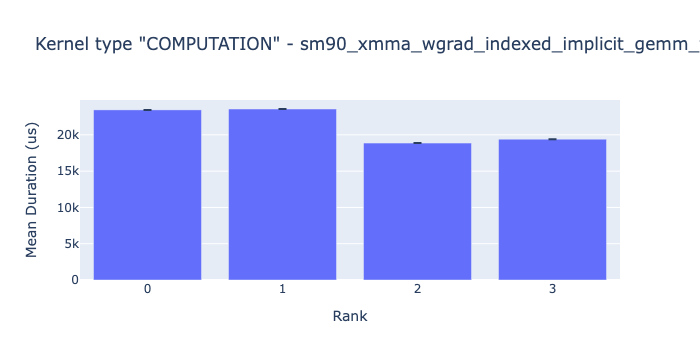

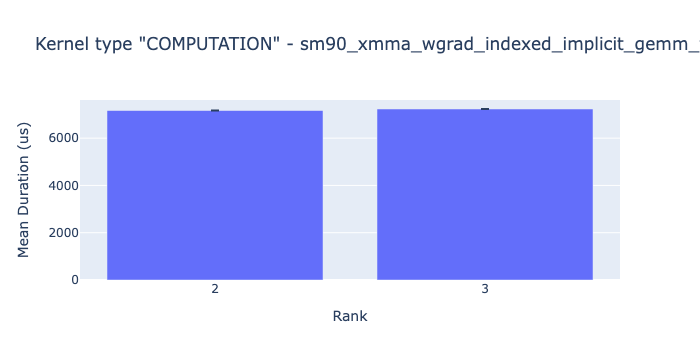

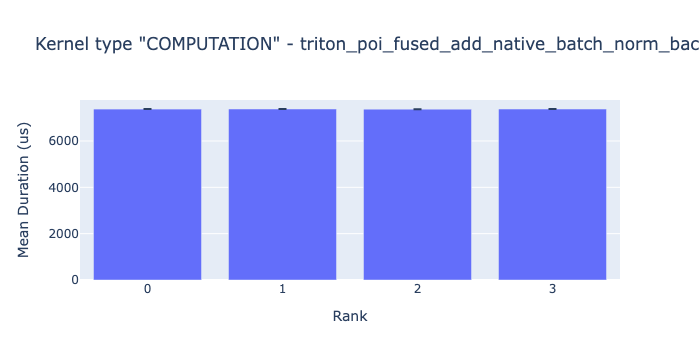

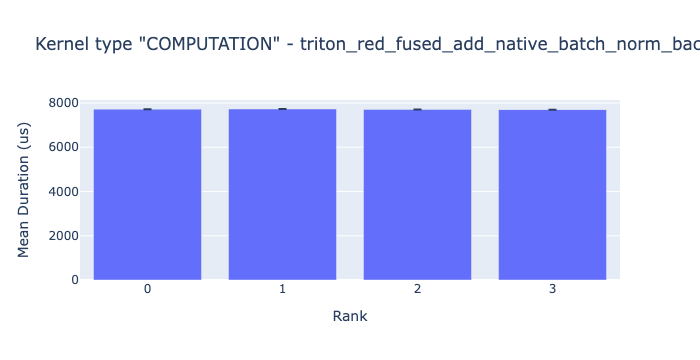

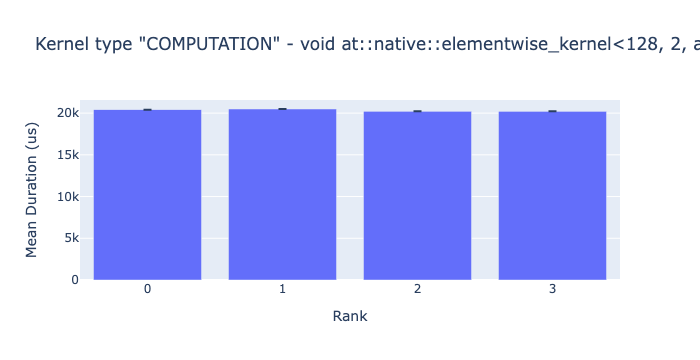

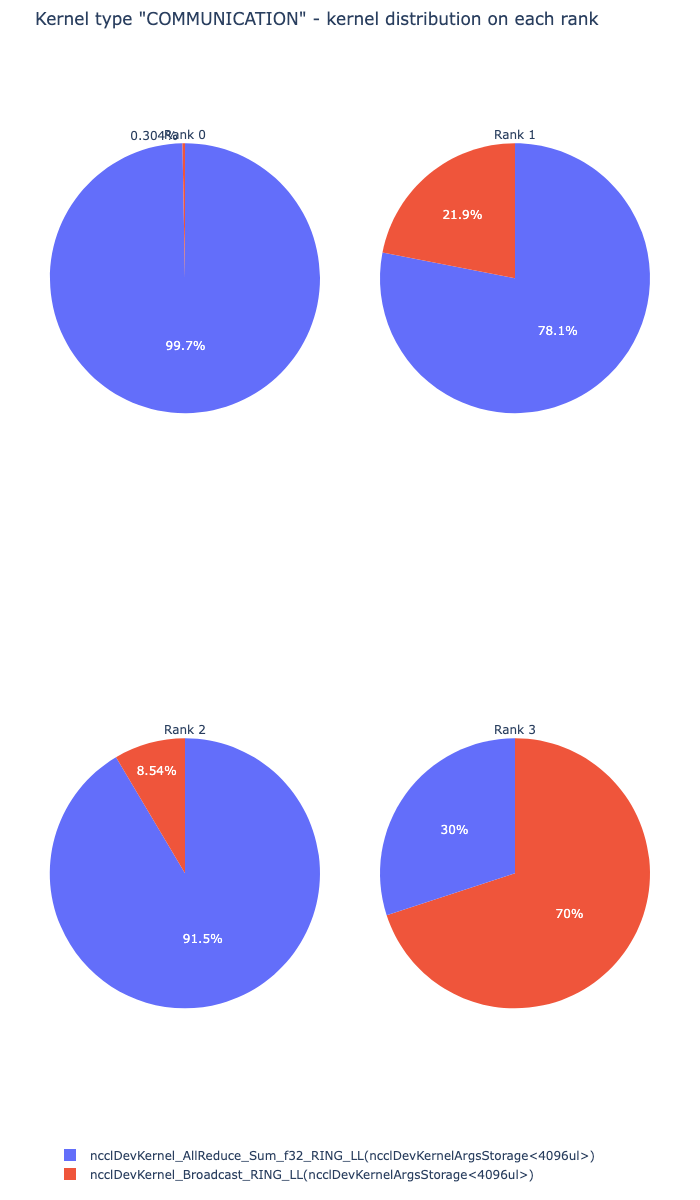

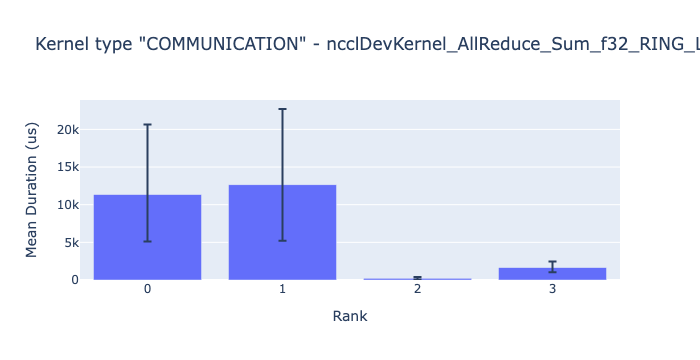

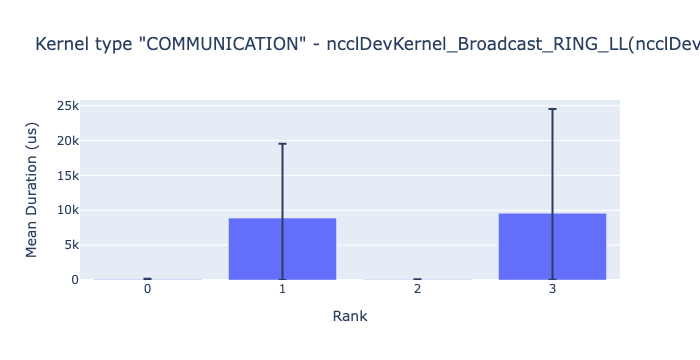

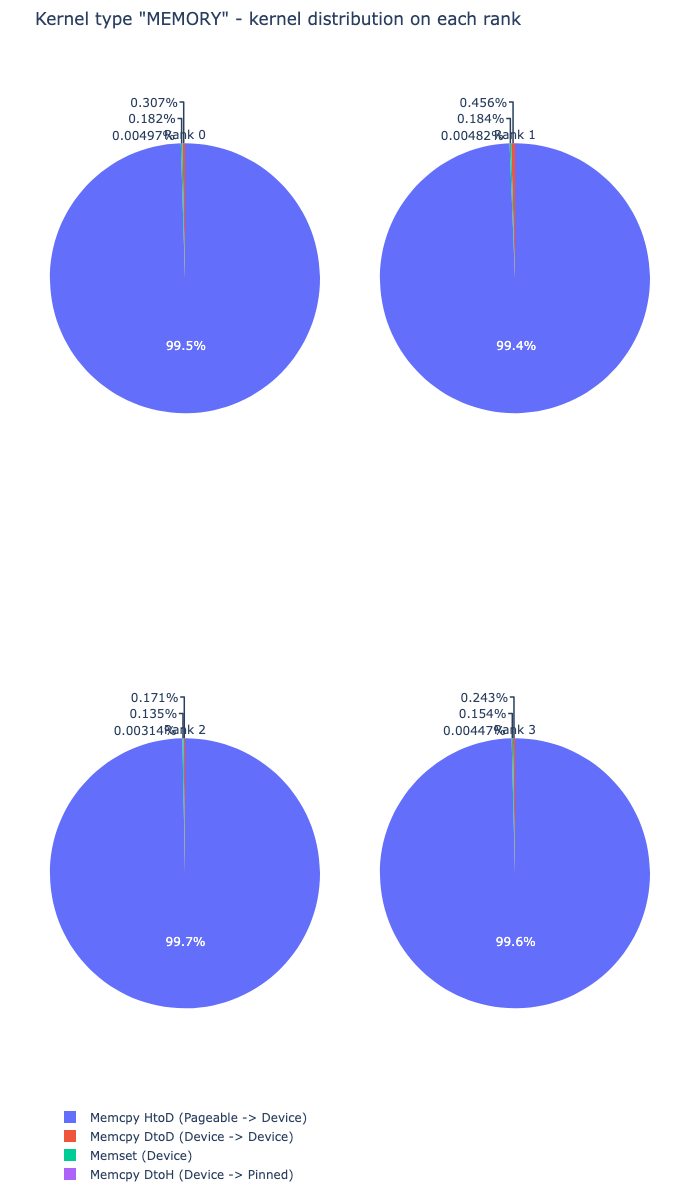

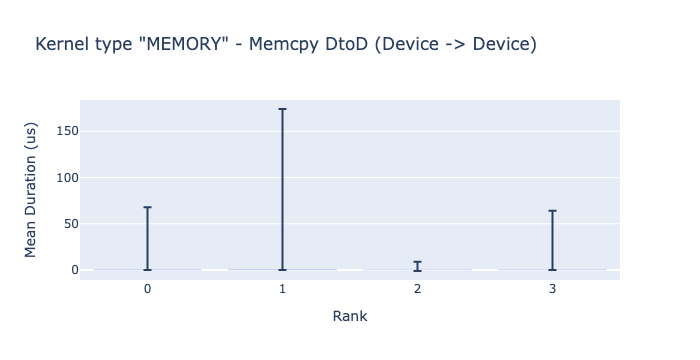

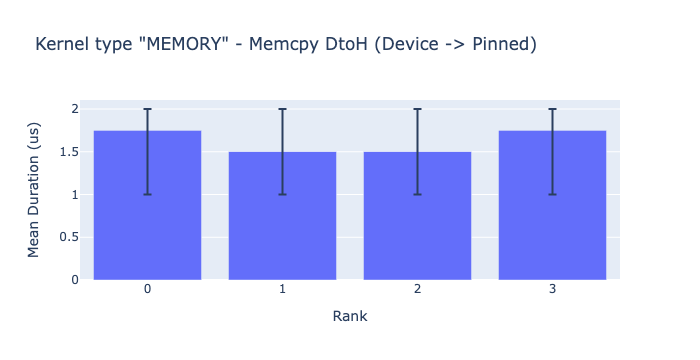

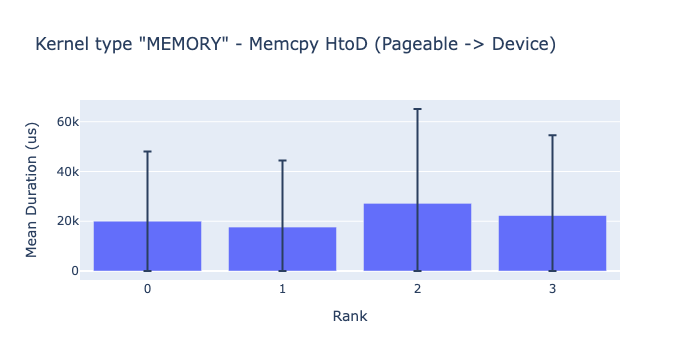

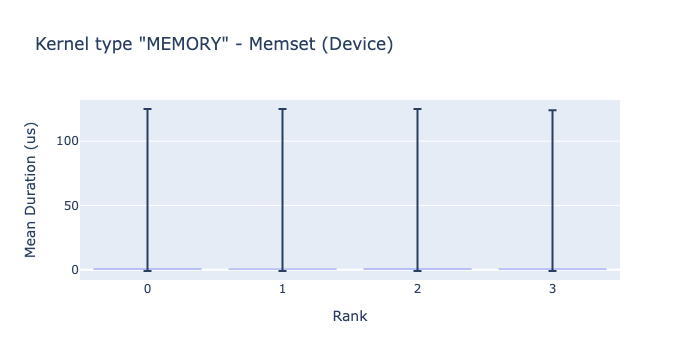

(                                         kernel_type      sum  percentage
 0                                        COMPUTATION  1245715        56.9
 1                                             MEMORY   611721        27.9
 2              COMPUTATION overlapping COMMUNICATION   209235         9.6
 3                                      COMMUNICATION   122409         5.6
 4                   COMMUNICATION overlapping MEMORY     1293         0.1
 5  COMPUTATION overlapping COMMUNICATION overlapp...        2         0.0
 6                     COMPUTATION overlapping MEMORY        2         0.0,
                                                  name  sum (us)  max (us)  \
 0   ncclDevKernel_AllReduce_Sum_f32_RING_LL(ncclDe...  113402.0   20639.0   
 1   ncclDevKernel_AllReduce_Sum_f32_RING_LL(ncclDe...  126408.0   22708.0   
 2   ncclDevKernel_AllReduce_Sum_f32_RING_LL(ncclDe...    2282.0     382.0   
 3   ncclDevKernel_AllReduce_Sum_f32_RING_LL(ncclDe...   16439.0    2445.0   
 4   nccl

In [39]:
analyzer.get_gpu_kernel_breakdown()

- ## There are many other feature of HTA we could use to analyze these traces
- ## It's still information dense, and making concrete reccomendations for optimizations based on these outputs can take a lot of effort.
- ## Can we use AI to help narrow our focus in making optimizations?

# Trace Analysis with Brine

- ## Sharcnet offers Brine AIaaS to Alliance users
- ## Raw traces are too large and noisy for LLMs to make use of
- ## We can run HTA, package the analyses into a prompt and then get reccomendation about improvments, or where to look for improvements.

# Trace Analysis with Brine (and `torch-lab`)

- ## You've already seen how we can use this presentation's package to generate the example traces
- ## `torch-lab analyze-traces <trace_dir>` will perform several HTA analyses and package the results into a prompt
- ## Running with `--no-llm` will only generate the prompt and a small heuristic-based report, you can then use the prompt with another LLM to get the report

In [41]:
! torch-lab analyze-traces example-traces/single-gpu --no-llm

Scenario S2: 5 run(s): main-process, serial, serial-compiled, threaded-compiled, threaded-compiled-amp
Analyzing main-process ...
  main-process: done (6.3 s)
Analyzing serial ...
  serial: done (1.5 s)
Analyzing serial-compiled ...
  serial-compiled: done (2.5 s)
Analyzing threaded-compiled ...
  threaded-compiled: done (2.5 s)
Analyzing threaded-compiled-amp ...
  threaded-compiled-amp: done (2.8 s)
Trace diff against main-process (rank 0) ...
  main-process: 10 steps, flags: GPU_IDLE_HIGH, HOST_BOUND, NO_AMP_SUSPECTED
  serial: 10 steps, flags: NO_AMP_SUSPECTED
  serial-compiled: 10 steps, flags: GPU_IDLE_HIGH, HOST_BOUND, NO_AMP_SUSPECTED
  threaded-compiled: 10 steps, flags: HOST_BOUND, NO_AMP_SUSPECTED
  threaded-compiled-amp: 10 steps, flags: GPU_IDLE_HIGH, HOST_BOUND
Prompt: about 20,105 tokens (estimate).
Wrote report.md, bundle.md, bundle.json, prompt.md and run.log to hta-report


In [1]:
! cat hta-report/report.md

# Trace analysis report (flags only)

> No LLM report: run with --no-llm.

This report lists the rule-based flags computed from the traces. Full tables are in `bundle.md`.

## Summary

| run | step_time_ms | samples_per_s_per_gpu | step_time_vs_baseline_ms | step_time_vs_baseline_pct | speedup_vs_baseline |
|---|---:|---:|---:|---:|---:|
| main-process | 502.14 | 127.5 | 0 | 0 | 1 |
| serial | 251.05 | 254.9 | -251.09 | -50 | 2 |
| serial-compiled | 243.65 | 262.7 | -258.49 | -51.5 | 2.06 |
| threaded-compiled | 190.98 | 335.1 | -311.16 | -62 | 2.63 |
| threaded-compiled-amp | 170.99 | 374.3 | -331.15 | -65.9 | 2.94 |

## main-process

- **GPU_IDLE_HIGH** (high): GPU idle 47.9% of the GPU timeline (229.26 ms/step). _Threshold: GPU idle > 20% of the GPU timeline._
- **HOST_BOUND** (high): host wait is 99.1% of GPU idle time; GPU idle 47.9% (the GPU waits for the CPU: data loading or Python overhead). _Threshold: host wait > 50% of GPU idle time, with GPU idle ≥ 5%._
- **NO_AMP_SUSPECTED

In [2]:
! torch-lab analyze-traces example-traces/single-gpu

Scenario S2: 5 run(s): main-process, serial, serial-compiled, threaded-compiled, threaded-compiled-amp
Analyzing main-process ...
  main-process: done (6.1 s)
Analyzing serial ...
  serial: done (1.4 s)
Analyzing serial-compiled ...
  serial-compiled: done (2.5 s)
Analyzing threaded-compiled ...
  threaded-compiled: done (2.4 s)
Analyzing threaded-compiled-amp ...
  threaded-compiled-amp: done (2.8 s)
Trace diff against main-process (rank 0) ...
  main-process: 10 steps, flags: GPU_IDLE_HIGH, HOST_BOUND, NO_AMP_SUSPECTED
  serial: 10 steps, flags: NO_AMP_SUSPECTED
  serial-compiled: 10 steps, flags: GPU_IDLE_HIGH, HOST_BOUND, NO_AMP_SUSPECTED
  threaded-compiled: 10 steps, flags: HOST_BOUND, NO_AMP_SUSPECTED
  threaded-compiled-amp: 10 steps, flags: GPU_IDLE_HIGH, HOST_BOUND
Prompt: about 20,105 tokens (estimate).
Checking model DeepSeek-V4-Flash-0731 on Brine ...
Asking Brine for the report (this can take a minute) ...
Brine answered in 10.4 s; usage: {"completion_tokens": 2245, "prom

In [3]:
! cat hta-report/report.md

# Trace analysis report

_Written by DeepSeek-V4-Flash-0731 on SHARCNET Brine from `bundle.md`. Numbers come from the bundle; check them there and in the trace viewer before acting on them._

## Summary

The 5 runs form a clear optimization ladder: fixing per-step host synchronization (`.item()` calls) and data-loading overhead explains most of the speedup from main-process to serial, while torch.compile and AMP further reduce GPU kernel time. The best run (threaded-compiled-amp, 170.99 ms/step, 374.3 samples/s) is now bottlenecked by host-side data loading (HOST_BOUND flag fired at high severity), not by GPU compute.

## Findings

### 1. Runtime differences (ranked by step-time impact)

**Finding 1: Per-step host synchronization (`.item()` calls) is the single largest cost in main-process and explains most of the gap to serial.**
- Evidence: Trace diff main-process vs. serial shows `aten::item` at 228.22 ms/step (606.6 calls) dropping to 229.37 ms/step (1 call) — the calls were reduce

- ## Traces should be laid out in a well structured way with one directory per run
- ## The package will infer what sort of comparison you are looking for:
    - ## single run - suggested improvements
    - ## several runs - comparative analysis bewteen the runs, how bottleneck improve,
    - ## single-GPU or multi-GPU

In [9]:
! torch-lab analyze-traces example-traces/multi-gpu/1_node_4_gpus

Scenario S3: 1 run(s): 1_node_4_gpus (4 ranks)
Analyzing 1_node_4_gpus ...
  1_node_4_gpus: done (1.8 s)
  1_node_4_gpus: 3 steps, flags: HOST_BOUND, MEMCPY_HIGH, NO_AMP_SUSPECTED
Prompt: about 11,915 tokens (estimate).
Checking model DeepSeek-V4-Flash-0731 on Brine ...
Asking Brine for the report (this can take a minute) ...
Brine answered in 8.9 s; usage: {"completion_tokens": 2275, "prompt_tokens": 8835, "total_tokens": 11110}
Wrote report.md, bundle.md, bundle.json, prompt.md and run.log to hta-report


In [10]:
! cat hta-report/report.md

# Trace analysis report

_Written by DeepSeek-V4-Flash-0731 on SHARCNET Brine from `bundle.md`. Numbers come from the bundle; check them there and in the trace viewer before acting on them._

## Summary

The run is **MEMCPY_HIGH** (high severity) and **NO_AMP_SUSPECTED** (medium severity), with a minor **HOST_BOUND** (low severity) issue. The GPU spends 25.7% of kernel time on host-to-device copies, and 96.6% of GEMM/conv time runs in TF32 despite the H100's fp16/bf16 tensor cores. Distributed communication is negligible (0.5% of GPU time on the slowest rank), so the bottleneck is single-GPU efficiency, not DDP.

## Findings

### 1. MEMCPY_HIGH (high severity) — Host-to-device copies dominate GPU time
- **Evidence:** Flag `MEMCPY_HIGH` fired (high severity): rank 2 shows host<->device memcpy at 25.7% of GPU kernel time. The kernel breakdown shows `Memcpy HtoD (Pageable -> Device)` at 63.49 ms/step (25.7% of GPU time), with only 3 calls/step at ~21 ms each. The launch stats confirm H2D+

In [11]:
! torch-lab analyze-traces example-traces/multi-gpu

Scenario S4: 2 runs: 1_node_4_gpus (4 ranks), 2_nodes_4_gpus (4 ranks)
Analyzing 1_node_4_gpus ...
  1_node_4_gpus: done (1.7 s)
Analyzing 2_nodes_4_gpus ...
  2_nodes_4_gpus: done (1.7 s)
Trace diff against 1_node_4_gpus (rank 0) ...
  1_node_4_gpus: 3 steps, flags: HOST_BOUND, MEMCPY_HIGH, NO_AMP_SUSPECTED
  2_nodes_4_gpus: 3 steps, flags: HOST_BOUND, MEMCPY_HIGH, NO_AMP_SUSPECTED
Prompt: about 17,924 tokens (estimate).
Checking model DeepSeek-V4-Flash-0731 on Brine ...
Asking Brine for the report (this can take a minute) ...
Brine answered in 9.6 s; usage: {"completion_tokens": 2224, "prompt_tokens": 14377, "total_tokens": 16601}
Wrote report.md, bundle.md, bundle.json, prompt.md and run.log to hta-report


In [12]:
! cat hta-report/report.md

# Trace analysis report

_Written by DeepSeek-V4-Flash-0731 on SHARCNET Brine from `bundle.md`. Numbers come from the bundle; check them there and in the trace viewer before acting on them._

## Summary

The 2-node run is 5.9% faster than the 1-node baseline (step time 266.54 ms vs 283.15 ms, throughput 7,683.6 vs 7,232.8 samples/s across all GPUs), despite using the same 4 GPUs. The speedup comes primarily from reduced communication cost (median-rank exposed communication drops from 15.12 to 7.75 ms/step) and lower memcpy overhead, while compute time is nearly identical. Both runs share the same dominant bottlenecks: MEMCPY_HIGH (high severity) and NO_AMP_SUSPECTED (medium), with HOST_BOUND as a minor issue.

## Findings

### 1. MEMCPY_HIGH (high severity, both runs) — dominant bottleneck
- **1_node_4_gpus**: host↔device memcpy is 25.7% of GPU kernel time (63.49 ms/step of Memcpy HtoD, 3 calls/step at ~21 ms each).
- **2_nodes_4_gpus**: host↔device memcpy is 20.3% of GPU kernel time (